Библиотеки

In [861]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from collections import Counter
import string
from itertools import product
import random
import pandas as pd
import re


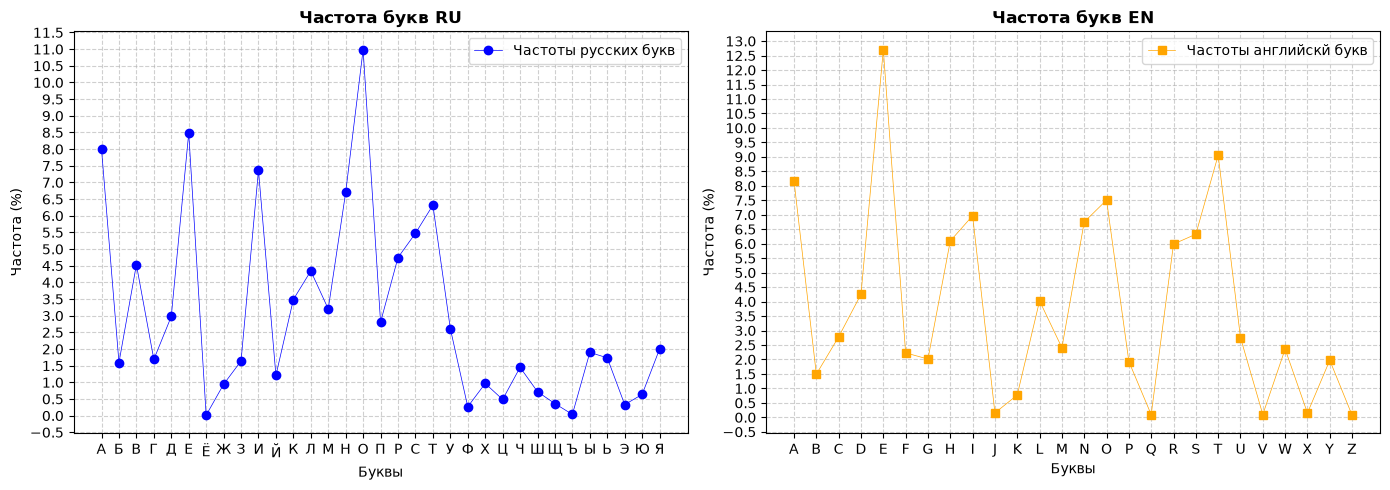

In [862]:
data_ru = {
    'А': 7.998,
    'Б': 1.592,
    'В': 4.533,
    'Г': 1.687,
    'Д': 2.977,
    'Е': 8.483,
    'Ё': 0.013,
    'Ж': 0.940,
    'З': 1.641,
    'И': 7.367,
    'Й': 1.208,
    'К': 3.486,
    'Л': 4.343,
    'М': 3.203,
    'Н': 6.700,
    'О': 10.983,
    'П': 2.804,
    'Р': 4.746,
    'С': 5.473,
    'Т': 6.318,
    'У': 2.615,
    'Ф': 0.267,
    'Х': 0.966,
    'Ц': 0.486,
    'Ч': 1.450,
    'Ш': 0.718,
    'Щ': 0.361,
    'Ъ': 0.037,
    'Ы': 1.898,
    'Ь': 1.735,
    'Э': 0.331,
    'Ю': 0.638,
    'Я': 2.001
}

data_en = {
    'A': 8.167,
    'B': 1.492,
    'C': 2.782,
    'D': 4.253,
    'E': 12.702,
    'F': 2.228,
    'G': 2.015,
    'H': 6.094,
    'I': 6.966,
    'J': 0.153,
    'K': 0.772,
    'L': 4.025,
    'M': 2.406,
    'N': 6.749,
    'O': 7.507,
    'P': 1.929,
    'Q': 0.095,
    'R': 5.987,
    'S': 6.327,
    'T': 9.056,
    'U': 2.758,
    'V': 0.098,
    'W': 2.360,
    'X': 0.150,
    'Y': 1.974,
    'Z': 0.074
}

# Создаем сетку: 1 строка, 2 столбца для двух раздельных графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.yaxis.set_major_locator(MultipleLocator(0.5))
ax2.yaxis.set_major_locator(MultipleLocator(0.5))
# --- ГРАФИК 1: Левый (Русские буквы) ---
# Передаем ключи (буквы) на ось X, значения (частоты) на ось Y
ax1.plot(list(data_ru.keys()), list(data_ru.values()), color='blue', marker='o', linewidth=0.5)
ax1.set_title('Частота букв RU', fontsize=12, fontweight='bold')
ax1.set_xlabel('Буквы')
ax1.set_ylabel('Частота (%)')
ax1.grid(True, linestyle='--', alpha=0.6) # Включаем сетку
ax1.legend(["Частоты русских букв"])
# --- ГРАФИК 2: Правый (Английские буквы) ---
ax2.plot(list(data_en.keys()), list(data_en.values()), color='orange', marker='s', linewidth=0.5) # marker='s' — квадраты
ax2.set_title('Частота букв EN', fontsize=12, fontweight='bold')
ax2.set_xlabel('Буквы')
ax2.set_ylabel('Частота (%)')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(["Частоты английскй букв"])

# Автовыравнивание, чтобы графики не налезали друг на друга
plt.tight_layout()


# Показываем окно с двумя графиками
plt.show()



Функция анализа частот символов в тексте

In [863]:
def analize_chastot(text):
    if text == "" or text==None:
        text = " "

    if type(text) != str:
        text = str(text)
    # 3. Подсчет количества каждого символа
    # Counter вернет структуру вида: {'П': 5, 'Р': 3, 'И': 4...}
    char_counts = Counter(text.upper())

    # Всего символов в очищенном тексте (нужно для расчета процентов)
    total_chars = len(text.upper())

    # 4. Переводим абсолютное количество в проценты (частоту)
    # Создаем итоговый словарь {буква: процент_встречи}
    char_frequencies = {}
    for char, count in char_counts.items():
        percentage = (count / total_chars) * 100
        char_frequencies[char] = round(percentage, 2) # Округляем до 2 знаков

    # 5. Сортируем словарь по убыванию частоты для красивого графика
    # (sorted вернет список кортежей, dict() превратит его обратно в словарь)
    # char_frequencies = dict(sorted(char_frequencies.items(), key=lambda item: item[0]))
    char_frequencies = dict(sorted(char_frequencies.items()))

    # Выводим результат
    # print("\nИтоговый словарь частот:")
    # print(char_frequencies)
    return char_frequencies

Функция рисования графика по частотам из функции анализа частот

In [864]:
def graphic(data, shag, title, labelX, labelY, color, marker, osx=14, osy=5):
    plt.figure(figsize=(osx, osy)) 
    #заменяем символы пробела
    x_labels = [("·" if key == " " else key) for key in data.keys()]
    
    plt.plot(x_labels, list(data.values()), color=color, marker=marker)
    plt.gca().yaxis.set_major_locator(MultipleLocator(shag))

    # Настройки для понятности
    plt.title(title)
    plt.xlabel(labelX)
    plt.ylabel(labelY)
    plt.grid(True, linestyle='--', alpha=0.6)

    # Показываем результат
    plt.show()


На одном графике более одного

In [ ]:

def graphic_more(data_list, shag, title, labelX, labelY):
    plt.figure(figsize=(14, 6))

    # Единый порядок символов для всех графиков
    alphabet = sorted(set(
        char
        for data, name, color, marker in data_list
        for char in data.keys()
    ))

    x = list(range(len(alphabet)))

    for data, name, color, marker in data_list:
        # Если символа нет в словаре, его частота равна 0
        y = [data.get(char, 0) for char in alphabet]

        plt.plot(
            x, y,
            label=name,
            color=color,
            marker=marker,
            markersize=4
        )

    plt.title(title)
    plt.xlabel(labelX)
    plt.ylabel(labelY)

    plt.xticks(x, alphabet)
    plt.gca().yaxis.set_major_locator(MultipleLocator(shag))

    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


Функция вывода таблицей

In [866]:
def print_table(encrypt_map, index, columns_per_table=20):
    chars = list(encrypt_map.keys())
    codes = list(encrypt_map.values())

    for i in range(0, len(chars), columns_per_table):
        table = pd.DataFrame(
            [codes[i:i + columns_per_table]],
            columns=[char.upper() for char in chars[i:i + columns_per_table]],
            index=[index]
        )

        display(table)

Функция сохранения в файл

In [867]:

def save_text(text, filename):
    with open(filename, 'w', encoding='utf-8') as file:
        file.write(text)
        
    print(f"Текст сохранён в файл: {filename}")


Функция шифрования шифром Цезаря

In [868]:
def caesar_cipher(text, shift, action, lang):
    """
    Шифрует или расшифровывает текст шифром Цезаря с произвольным сдвигом.
    lang: 'ru' (кириллица) или 'en' (латиница)
    action: 'encrypt' (зашифровать) или 'decrypt' (расшифровать)
    """
    # Выбираем алфавит в зависимости от языка
    if lang == 'ru':
        lower_alphabet = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"
        upper_alphabet = "АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯ"
    elif lang == 'en':
        lower_alphabet = string.ascii_lowercase
        upper_alphabet = string.ascii_uppercase
    else:
        raise ValueError("Выберите ru или en, других языков нет")

    if action not in ('encrypt', 'decrypt'):
            raise ValueError("Неизвестное действие, выберите 'encrypt' или 'decrypt'")
    
    size = len(lower_alphabet)
    # Корректируем сдвиг (на случай, если пользователь ввел число больше длины алфавита)
    shift = shift % size
    
    # Если нужно расшифровать — просто инвертируем сдвиг
    if action == 'decrypt':
        shift = -shift

    # Создаем сдвинутые алфавиты с помощью срезов строки
    shifted_lower = lower_alphabet[shift:] + lower_alphabet[:shift]
    shifted_upper = upper_alphabet[shift:] + upper_alphabet[:shift]
    
    # Объединяем оба регистра в одну таблицу замены
    orig_chars = lower_alphabet + upper_alphabet
    shifted_chars = shifted_lower + shifted_upper
    
    trans_table = str.maketrans(orig_chars, shifted_chars)
    
    return text.translate(trans_table)

Функция шифрования символами и Атбаш

In [869]:

def substitution_cipher(text, cipher, mode):
    """
    Шифрует или расшифровывает текст символьным шифром и Атбаш.
    lang: 'atbash' (Атбаш) или 'symbols' (символьный)
    action: 'encrypt' (зашифровать) или 'decrypt' (расшифровать)
    """

    # Исходный алфавит
    alphabet = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"

    # Выбор алфавита замены
    if cipher == "atbash":
        replacement = alphabet[::-1]

    elif cipher == "symbols":
        replacement = "✂✁✃✄✆✇✈✉✌✍✎✏✐✑✒✓✔✕✖✗✘✙✚✛✜✝✞✟✠✡✢✣✤"

    else:
        raise ValueError("Неизвестный тип шифра")

    # Проверка соответствия алфавитов
    if len(alphabet) != len(replacement):
        raise ValueError("Алфавиты имеют разную длину")

    if len(set(replacement)) != len(replacement):
        raise ValueError("В алфавите замены есть повторяющиеся символы")

    # Для шифрования переводим текст в нижний регистр
    if mode == "encrypt":
        text = text.lower()
        table = str.maketrans(alphabet, replacement)

    # Для расшифровки используем обратную таблицу
    elif mode == "decrypt":
        table = str.maketrans(replacement, alphabet)

    else:
        raise ValueError("Неизвестный режим работы")

    return text.translate(table)

Функция шифрования Виженером

In [870]:

def vigenere_cipher(text, key, action, lang):
    """
    Шифрует или расшифровывает текст шифром Виженера.
    key: ключ слово для шифра. на русском использовать русское, на английском английское, 
    в случае русского ключа для английского и наоборот не заработает.
    action: 'encrypt' (зашифровать) или 'decrypt' (расшифровать).
    lang: 'ru' (кириллица) или 'en' (латиница).
    """
    # Выбираем алфавит
    if lang == 'ru':
        alphabet = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"
    elif lang == 'en':
        alphabet = "abcdefghijklmnopqrstuvwxyz"
    else:
        raise ValueError("Неизвестный язык")

    if action not in ('encrypt', 'decrypt'):
        raise ValueError("Неизвестное действие")

    # Подготавливаем ключ
    key = key.lower()

    if not key:
        raise ValueError("Ключ не может быть пустым")

    # Создаём словарь: буква -> её позиция
    positions = {char: i for i, char in enumerate(alphabet)}

    # Проверяем ключ и заранее получаем позиции его букв
    if any(char not in positions for char in key):
        raise ValueError("Ключ содержит символы вне алфавита")

    key_positions = [positions[char] for char in key]

    result = []
    key_index = 0
    size = len(alphabet)

    for char in text:
        char_lower = char.lower()

        # Проверяем, есть ли символ в алфавите
        if char_lower not in positions:
            result.append(char)
            continue

        # Получаем позиции символов
        text_pos = positions[char_lower]
        key_pos = key_positions[key_index % len(key_positions)]

        # Вычисляем новую позицию
        if action == 'encrypt':
            new_pos = (text_pos + key_pos) % size
        else:
            new_pos = (text_pos - key_pos) % size

        # Восстанавливаем регистр
        new_char = alphabet[new_pos]

        if char.isupper():
            new_char = new_char.upper()

        result.append(new_char)

        # Ключ сдвигается только на буквах алфавита
        key_index += 1

    return ''.join(result)

Текст добавленный в файл для сокращения кода

In [871]:
with open('текст.txt', 'r', encoding='utf-8') as file:
    #заменяем переносы строк и табы на пробелы
    text = re.sub(r'\s+', ' ', file.read())

График частот оригинального текста

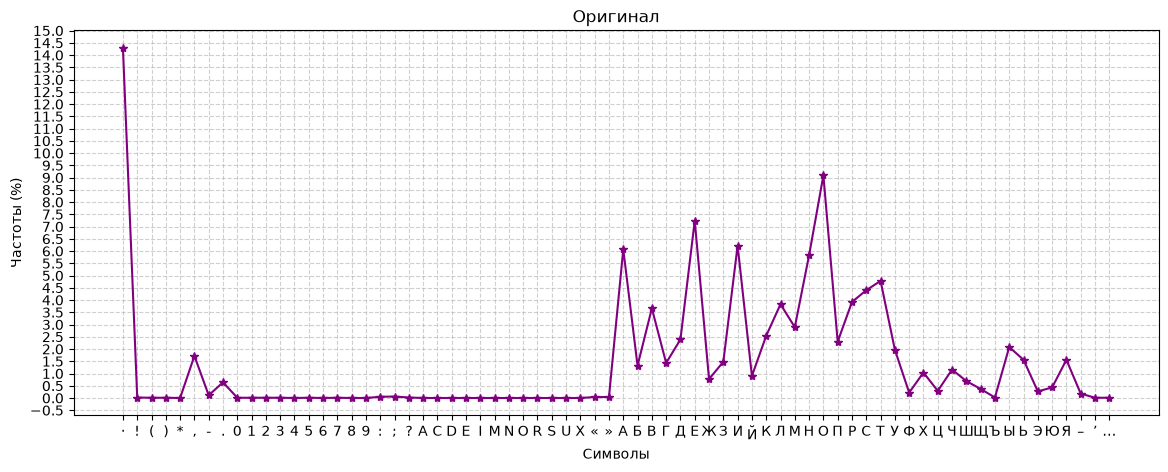

,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
Частота (%),14.29,0.02,0.01,0.01,0.0,1.72,0.11,0.64,0.01,0.01,0.01,0.01,0.0,0.01,0.0,0.01,0.0,0.0,0.05,0.06


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,А,Б,В,Г,Д
Частота (%),0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04,0.04,6.07,1.32,3.66,1.43,2.39


,Е,Ж,З,И,Й,К,Л,М,Н,О,П,Р,С,Т,У,Ф,Х,Ц,Ч,Ш
Частота (%),7.24,0.77,1.48,6.22,0.9,2.54,3.83,2.89,5.83,9.09,2.3,3.92,4.4,4.78,1.97,0.22,1.04,0.29,1.16,0.69


,Щ,Ъ,Ы,Ь,Э,Ю,Я,–,’,…
Частота (%),0.37,0.02,2.08,1.56,0.27,0.43,1.56,0.18,0.01,0.01


In [872]:
original_text_chastots = analize_chastot(text.lower())
graphic(original_text_chastots, 0.5, 'Оригинал', 'Символы', 'Частоты (%)', 'purple', '*')
print_table(original_text_chastots,"Частота (%)")

In [873]:

atbash_text = substitution_cipher(
    text,
    cipher="atbash",
    mode="encrypt"
)
save_text(atbash_text, "Lavkraft_Atbash.txt")

symbol_text = substitution_cipher(
    text,
    cipher="symbols",
    mode="encrypt"
)
save_text(symbol_text, "Lavkraft_symbols.txt")


cesar_text = caesar_cipher(text, 4, "encrypt", "ru")
save_text(cesar_text, "Lavkraft_Cesar.txt")

vifenere_text = vigenere_cipher(
        text,
        key = "шоггот",
        action="encrypt",
        lang='ru'
    )
save_text(vifenere_text, "Lavkraft_Vigenere.txt")

Текст сохранён в файл: Lavkraft_Atbash.txt
Текст сохранён в файл: Lavkraft_symbols.txt
Текст сохранён в файл: Lavkraft_Cesar.txt
Текст сохранён в файл: Lavkraft_Vigenere.txt


Графики с анализом частот зашифрованного текста

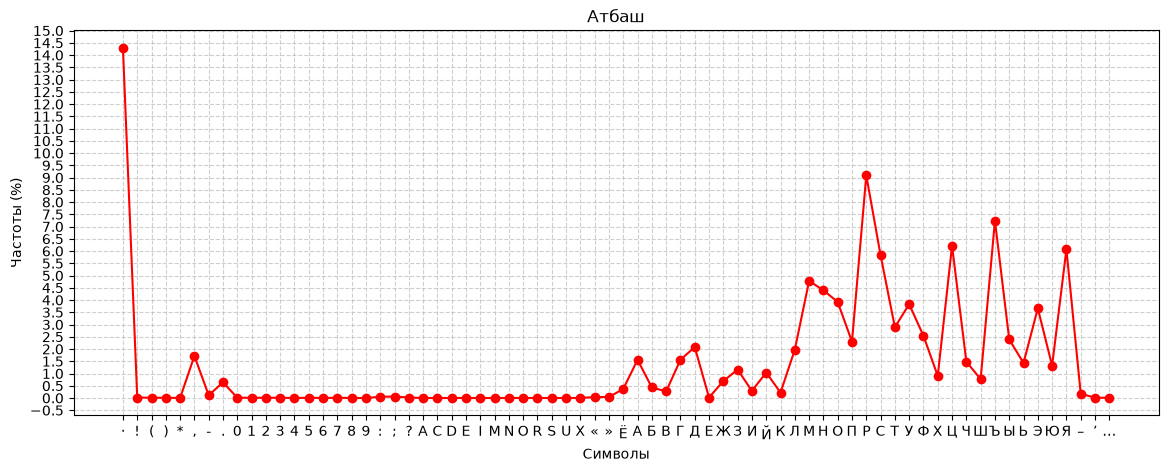

Частоты Атбаш символов в таблице


,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
частота(%),14.29,0.02,0.01,0.01,0.0,1.72,0.11,0.64,0.01,0.01,0.01,0.01,0.0,0.01,0.0,0.01,0.0,0.0,0.05,0.06


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,Ё,А,Б,В,Г
частота(%),0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04,0.04,0.37,1.56,0.43,0.27,1.56


,Д,Е,Ж,З,И,Й,К,Л,М,Н,О,П,Р,С,Т,У,Ф,Х,Ц,Ч
частота(%),2.08,0.02,0.69,1.16,0.29,1.04,0.22,1.97,4.78,4.4,3.92,2.3,9.09,5.83,2.89,3.83,2.54,0.9,6.22,1.48


,Ш,Ъ,Ы,Ь,Э,Ю,Я,–,’,…
частота(%),0.77,7.24,2.39,1.43,3.66,1.32,6.07,0.18,0.01,0.01


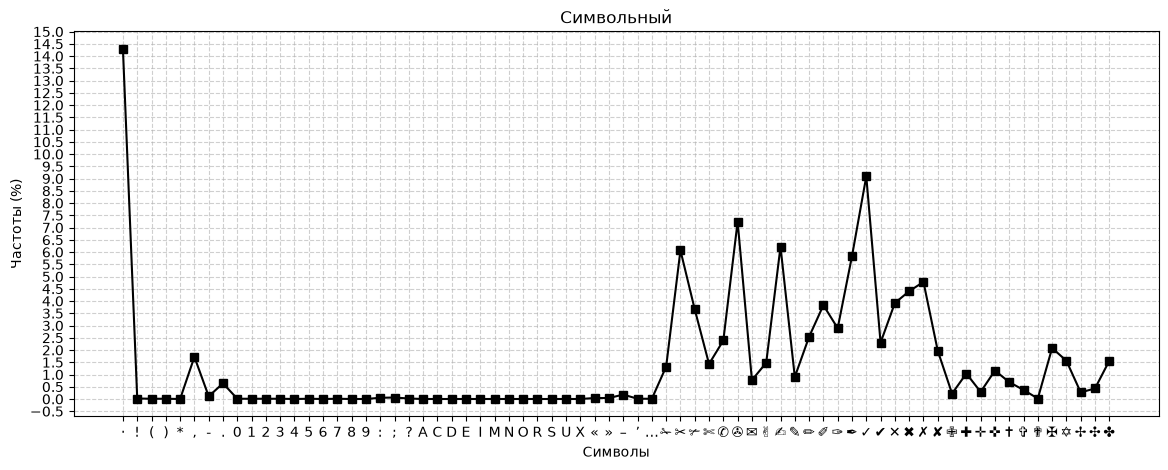

Частоты Символьный символов в таблице


,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
частота(%),14.29,0.02,0.01,0.01,0.0,1.72,0.11,0.64,0.01,0.01,0.01,0.01,0.0,0.01,0.0,0.01,0.0,0.0,0.05,0.06


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,–,’,…,✁,✂
частота(%),0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04,0.04,0.18,0.01,0.01,1.32,6.07


,✃,✄,✆,✇,✉,✌,✍,✎,✏,✐,✑,✒,✓,✔,✕,✖,✗,✘,✙,✚
частота(%),3.66,1.43,2.39,7.24,0.77,1.48,6.22,0.9,2.54,3.83,2.89,5.83,9.09,2.3,3.92,4.4,4.78,1.97,0.22,1.04


,✛,✜,✝,✞,✟,✠,✡,✢,✣,✤
частота(%),0.29,1.16,0.69,0.37,0.02,2.08,1.56,0.27,0.43,1.56


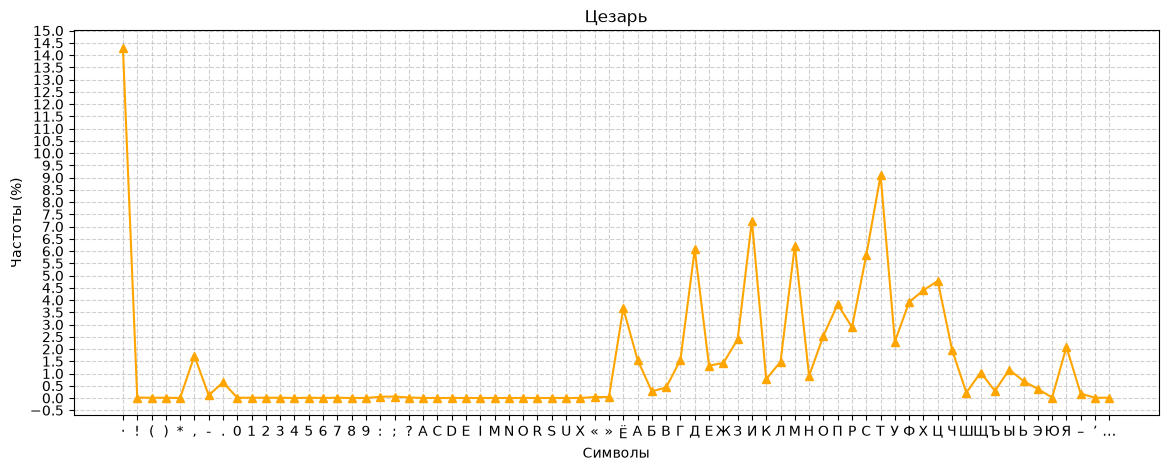

Частоты Цезарь символов в таблице


,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
частота(%),14.29,0.02,0.01,0.01,0.0,1.72,0.11,0.64,0.01,0.01,0.01,0.01,0.0,0.01,0.0,0.01,0.0,0.0,0.05,0.06


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,Ё,А,Б,В,Г
частота(%),0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04,0.04,3.66,1.56,0.27,0.43,1.56


,Д,Е,Ж,З,И,К,Л,М,Н,О,П,Р,С,Т,У,Ф,Х,Ц,Ч,Ш
частота(%),6.07,1.32,1.43,2.39,7.24,0.77,1.48,6.22,0.9,2.54,3.83,2.89,5.83,9.09,2.3,3.92,4.4,4.78,1.97,0.22


,Щ,Ъ,Ы,Ь,Э,Ю,Я,–,’,…
частота(%),1.04,0.29,1.16,0.69,0.37,0.02,2.08,0.18,0.01,0.01


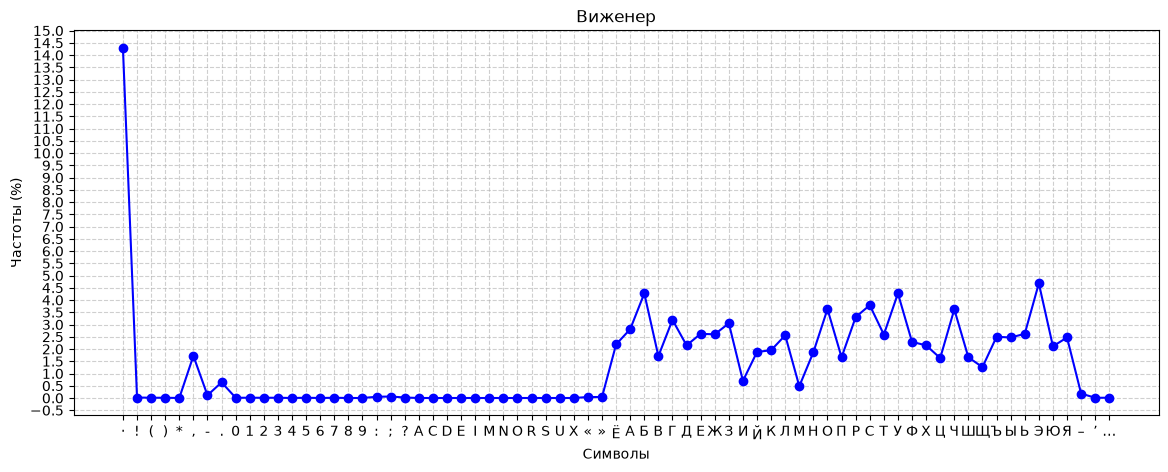

Частоты Виженер символов в таблице


,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
частота(%),14.29,0.02,0.01,0.01,0.0,1.72,0.11,0.64,0.01,0.01,0.01,0.01,0.0,0.01,0.0,0.01,0.0,0.0,0.05,0.06


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,Ё,А,Б,В,Г
частота(%),0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04,0.04,2.19,2.81,4.27,1.71,3.19


,Д,Е,Ж,З,И,Й,К,Л,М,Н,О,П,Р,С,Т,У,Ф,Х,Ц,Ч
частота(%),2.15,2.62,2.6,3.05,0.7,1.88,1.95,2.56,0.48,1.87,3.63,1.66,3.3,3.79,2.59,4.27,2.29,2.15,1.63,3.62


,Ш,Щ,Ъ,Ы,Ь,Э,Ю,Я,–,’,…
частота(%),1.66,1.26,2.5,2.47,2.62,4.68,2.11,2.47,0.18,0.01,0.01


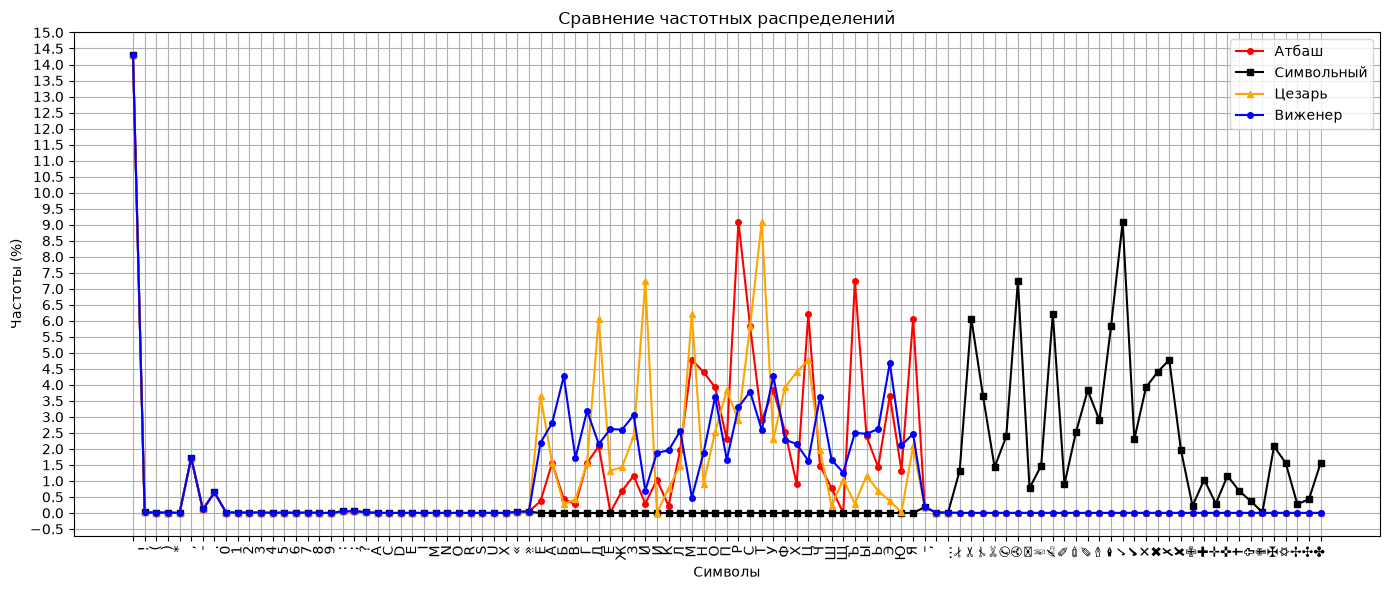

In [874]:

# Настройки графиков:
# (имя файла, название графика, цвет, маркер)
graphs = [
    ('Lavkraft_Atbash.txt', 'Атбаш', 'red', 'o'),
    ('Lavkraft_symbols.txt', 'Символьный', 'black', 's'),
    ('Lavkraft_Cesar.txt', 'Цезарь', 'orange', '^'),
    ('Lavkraft_Vigenere.txt', 'Виженер', 'blue', 'o')
]

data_list = []

for filename, title, color, marker in graphs:

    with open(filename, 'r', encoding='utf-8') as file:
        encrypted_text = file.read()
        
    char_frequencies = analize_chastot(encrypted_text)
    

    graphic(
        char_frequencies,
        0.5,
        title,
        'Символы',
        'Частоты (%)',
        color,
        marker
    )
    new_item = (char_frequencies, title, color,marker )

    data_list.append(new_item)
    print(f'Частоты {title} символов в таблице')
    print_table(char_frequencies, "частота(%)")





    # Частоты символов трёх текстов
# library_freq = analize_chastot(library_text)

# insert_freq = analize_chastot(inserted_text)

# message_freq = analize_chastot(insert_in_text)



# Формируем список графиков


graphic_more(
    data_list,
    0.5,
    "Сравнение частотных распределений",
    "Символы",
    "Частоты (%)"
)

Функции шифрования биограммами и триграммами

Функция создания таблицы замен

In [875]:

russian_alphabet = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"


def create_polygram_table(code_alphabet, group_size, seed=42):

    # Проверяем, что в кодовом алфавите нет повторов
    if len(set(code_alphabet)) != len(code_alphabet):
        raise ValueError("В кодовом алфавите есть повторы")

    # Генерируем все возможные сочетания
    all_codes = [
        ''.join(chars)
        for chars in product(code_alphabet, repeat=group_size)
    ]

    # Проверяем, достаточно ли комбинаций
    if len(all_codes) < len(russian_alphabet):
        raise ValueError("Недостаточно комбинаций для шифрования")

    # Перемешиваем комбинации
    generator = random.Random(seed)
    generator.shuffle(all_codes)

    # Берём столько кодов, сколько букв в русском алфавите
    selected_codes = all_codes[:len(russian_alphabet)]

    # Создаём таблицу шифрования
    encrypt_map = dict(zip(russian_alphabet, selected_codes))

    # Создаём таблицу расшифровки
    decrypt_map = {
        code: char
        for char, code in encrypt_map.items()
    }

    return encrypt_map, decrypt_map

def print_polygram_table(encrypt_map):
    table = pd.DataFrame(
        [list(encrypt_map.values())],
        columns=[char.upper() for char in encrypt_map.keys()],
        index=["Код"]
    )

    display(table)

Создание алфавита и вывод таблиц

In [876]:

# Кодовый алфавит
bigram_alphabet = "абвгде"
trigram_alphabet = "абвг"

# Создаём таблицу биграмм
bigram_encrypt_map, bigram_decrypt_map = create_polygram_table(
    bigram_alphabet,
    group_size=2,
    seed=42
)

# Создаём таблицу триграмм
trigram_encrypt_map, trigram_decrypt_map = create_polygram_table(
    trigram_alphabet,
    group_size=3,
    seed=42
)

# # Выводим таблицы
print("БИГРАММЫ")
print_table(bigram_encrypt_map, "Код")


print("\nТРИГРАММЫ")
print_table(trigram_encrypt_map, "Код")


БИГРАММЫ


,А,Б,В,Г,Д,Е,Ё,Ж,З,И,Й,К,Л,М,Н,О,П,Р,С,Т
Код,бг,ва,ае,дг,ев,гб,еа,дб,гд,дв,еб,бд,бе,дд,бв,гв,вд,ее,ба,да


,У,Ф,Х,Ц,Ч,Ш,Щ,Ъ,Ы,Ь,Э,Ю,Я
Код,аа,ед,вб,га,ав,ег,де,гг,аг,ге,ад,вв,вг



ТРИГРАММЫ


,А,Б,В,Г,Д,Е,Ё,Ж,З,И,Й,К,Л,М,Н,О,П,Р,С,Т
Код,ббг,бвб,абг,ббв,вгб,ваб,баг,гвг,вгв,авб,вва,бав,ввв,бгг,баа,ббб,вба,ввб,бгб,бба


,У,Ф,Х,Ц,Ч,Ш,Щ,Ъ,Ы,Ь,Э,Ю,Я
Код,авг,гав,вбг,гаа,ааг,бгв,бва,гбг,аба,гвб,гбв,габ,авв


Сама функция шифрования биограммами и триграммами

In [877]:

# Общая функция шифрования и расшифровки
def polygram_cipher(text, encrypt_map, decrypt_map, code_alphabet, group_size, mode):

    if mode == "encrypt":
        text = text.lower()
        result = []

        for char in text:
            # Если символ есть в таблице, заменяем его
            if char in encrypt_map:
                result.append(encrypt_map[char])
            else:
                # Остальные символы оставляем без изменений
                result.append(char)

        return ''.join(result)

    elif mode == "decrypt":
        result = []
        code_symbols = set(code_alphabet)
        i = 0

        while i < len(text):

            if text[i] in code_symbols:

                # Берём следующую пару или тройку
                code = text[i:i + group_size]

                if len(code) != group_size or code not in decrypt_map:
                    raise ValueError(f"Некорректный код: {code}")

                result.append(decrypt_map[code])
                i += group_size

            else:
                result.append(text[i])
                i += 1

        return ''.join(result)

    else:
        raise ValueError("Выберите encrypt или decrypt")


# Шифрование биграммами
def bigram_cipher(text, mode="encrypt"):
    return polygram_cipher(
        text,
        bigram_encrypt_map,
        bigram_decrypt_map,
        bigram_alphabet,
        2,
        mode
    )


# Шифрование триграммами
def trigram_cipher(text, mode="encrypt"):
    return polygram_cipher(
        text,
        trigram_encrypt_map,
        trigram_decrypt_map,
        trigram_alphabet,
        3,
        mode
    )


In [878]:
# Биграммы
bigram_text = bigram_cipher(text)
save_text(bigram_text, "Lavkraft_Bigram.txt")

# Триграммы
trigram_text = trigram_cipher(text)
save_text(trigram_text, "Lavkraft_Trigram.txt")
# Проверка дешифровки
# print(bigram_cipher(bigram_text, mode="decrypt"))
# print(trigram_cipher(trigram_text, mode="decrypt"))

Текст сохранён в файл: Lavkraft_Bigram.txt
Текст сохранён в файл: Lavkraft_Trigram.txt


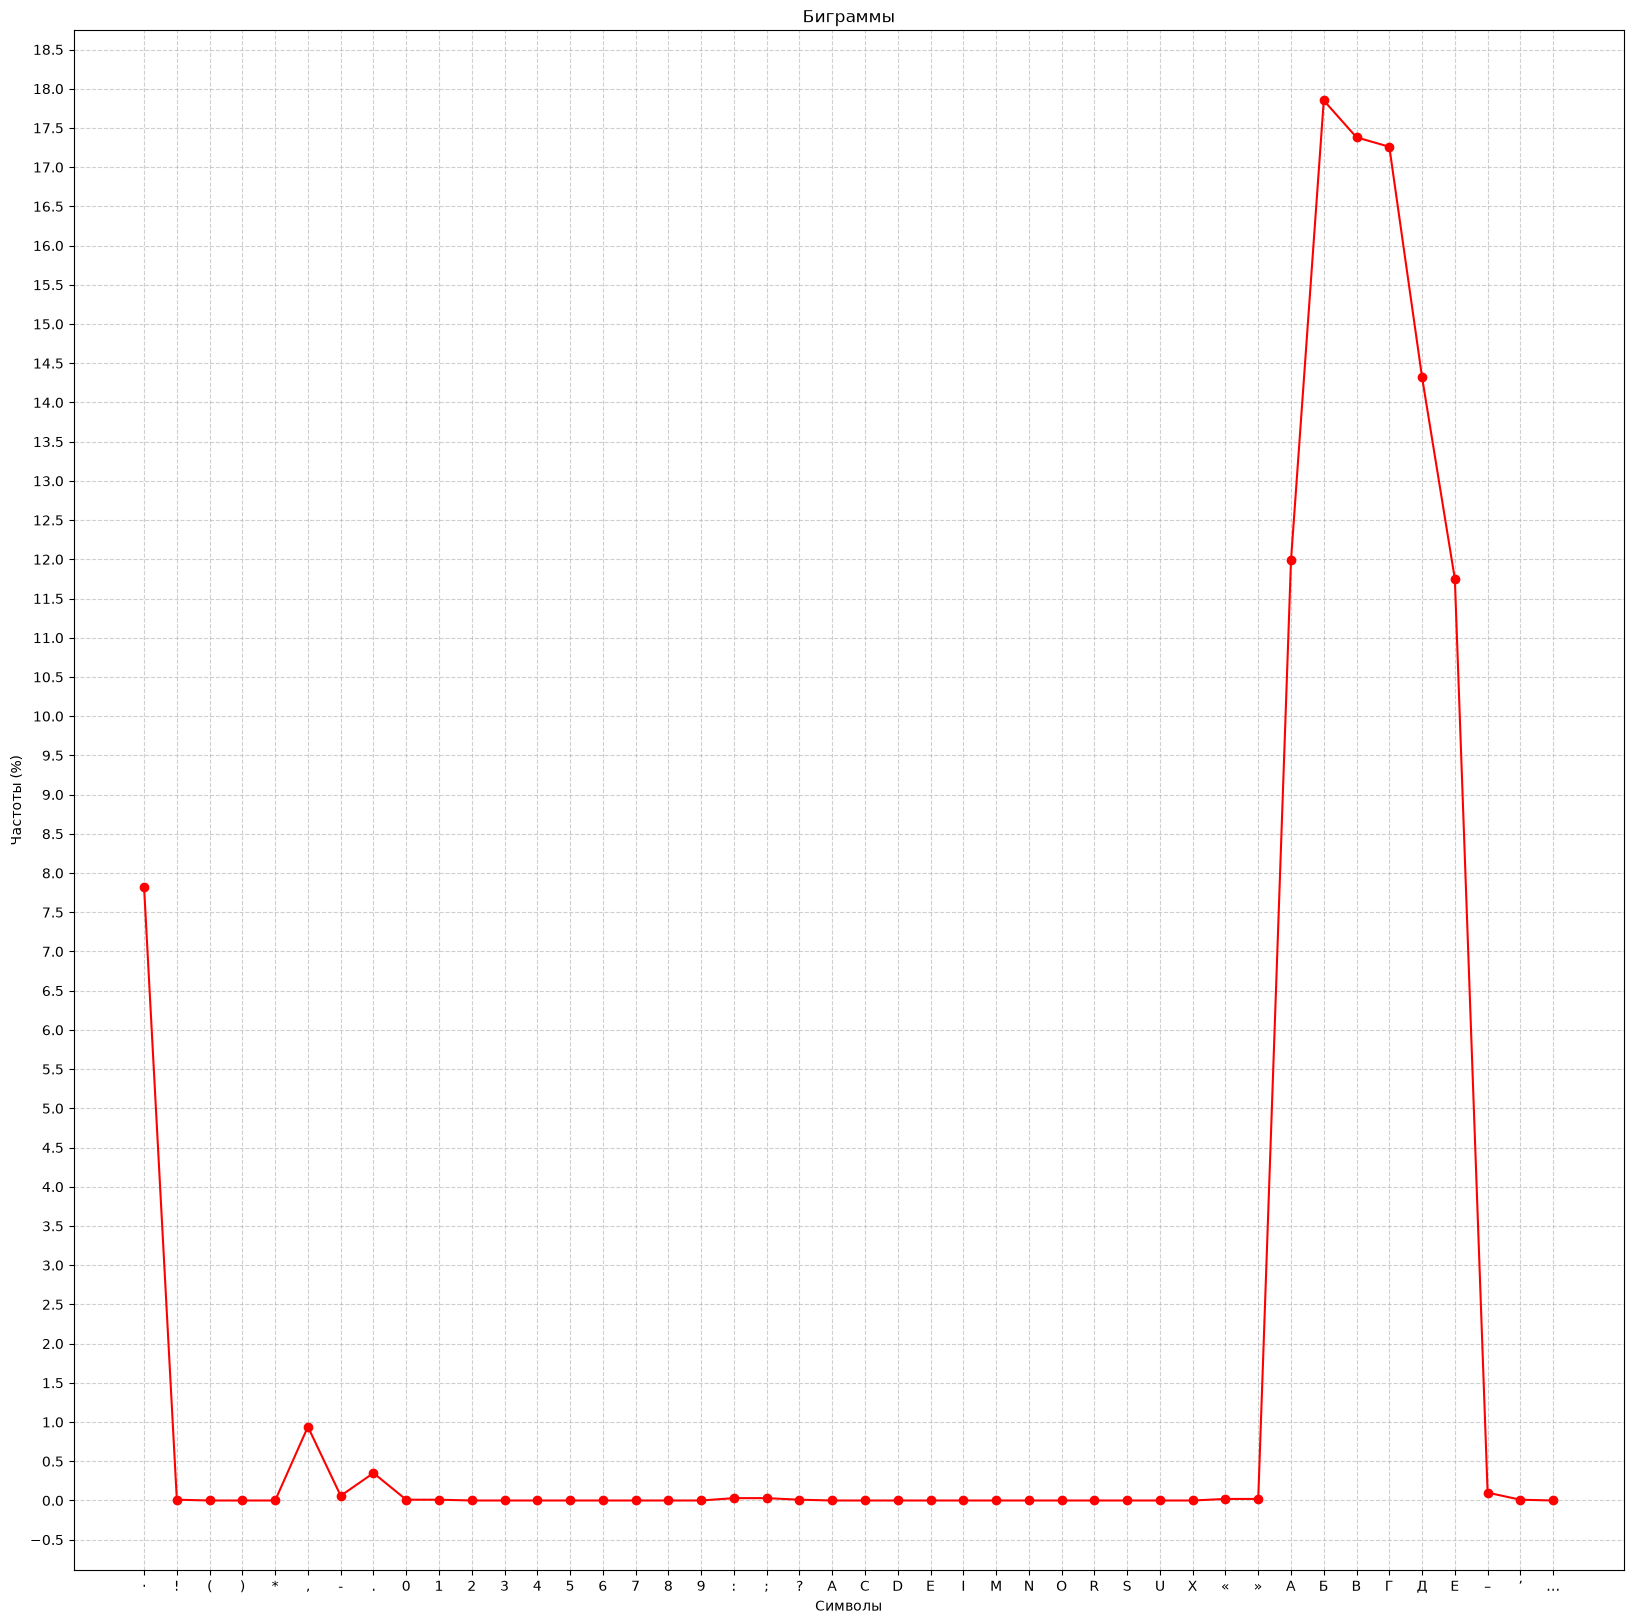

,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
Частота (%),7.82,0.01,0.0,0.0,0.0,0.94,0.06,0.35,0.01,0.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.03,0.03


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,А,Б,В,Г,Д
Частота (%),0.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02,0.02,11.99,17.85,17.38,17.26,14.32


,Е,–,’,…
Частота (%),11.75,0.1,0.01,0.0


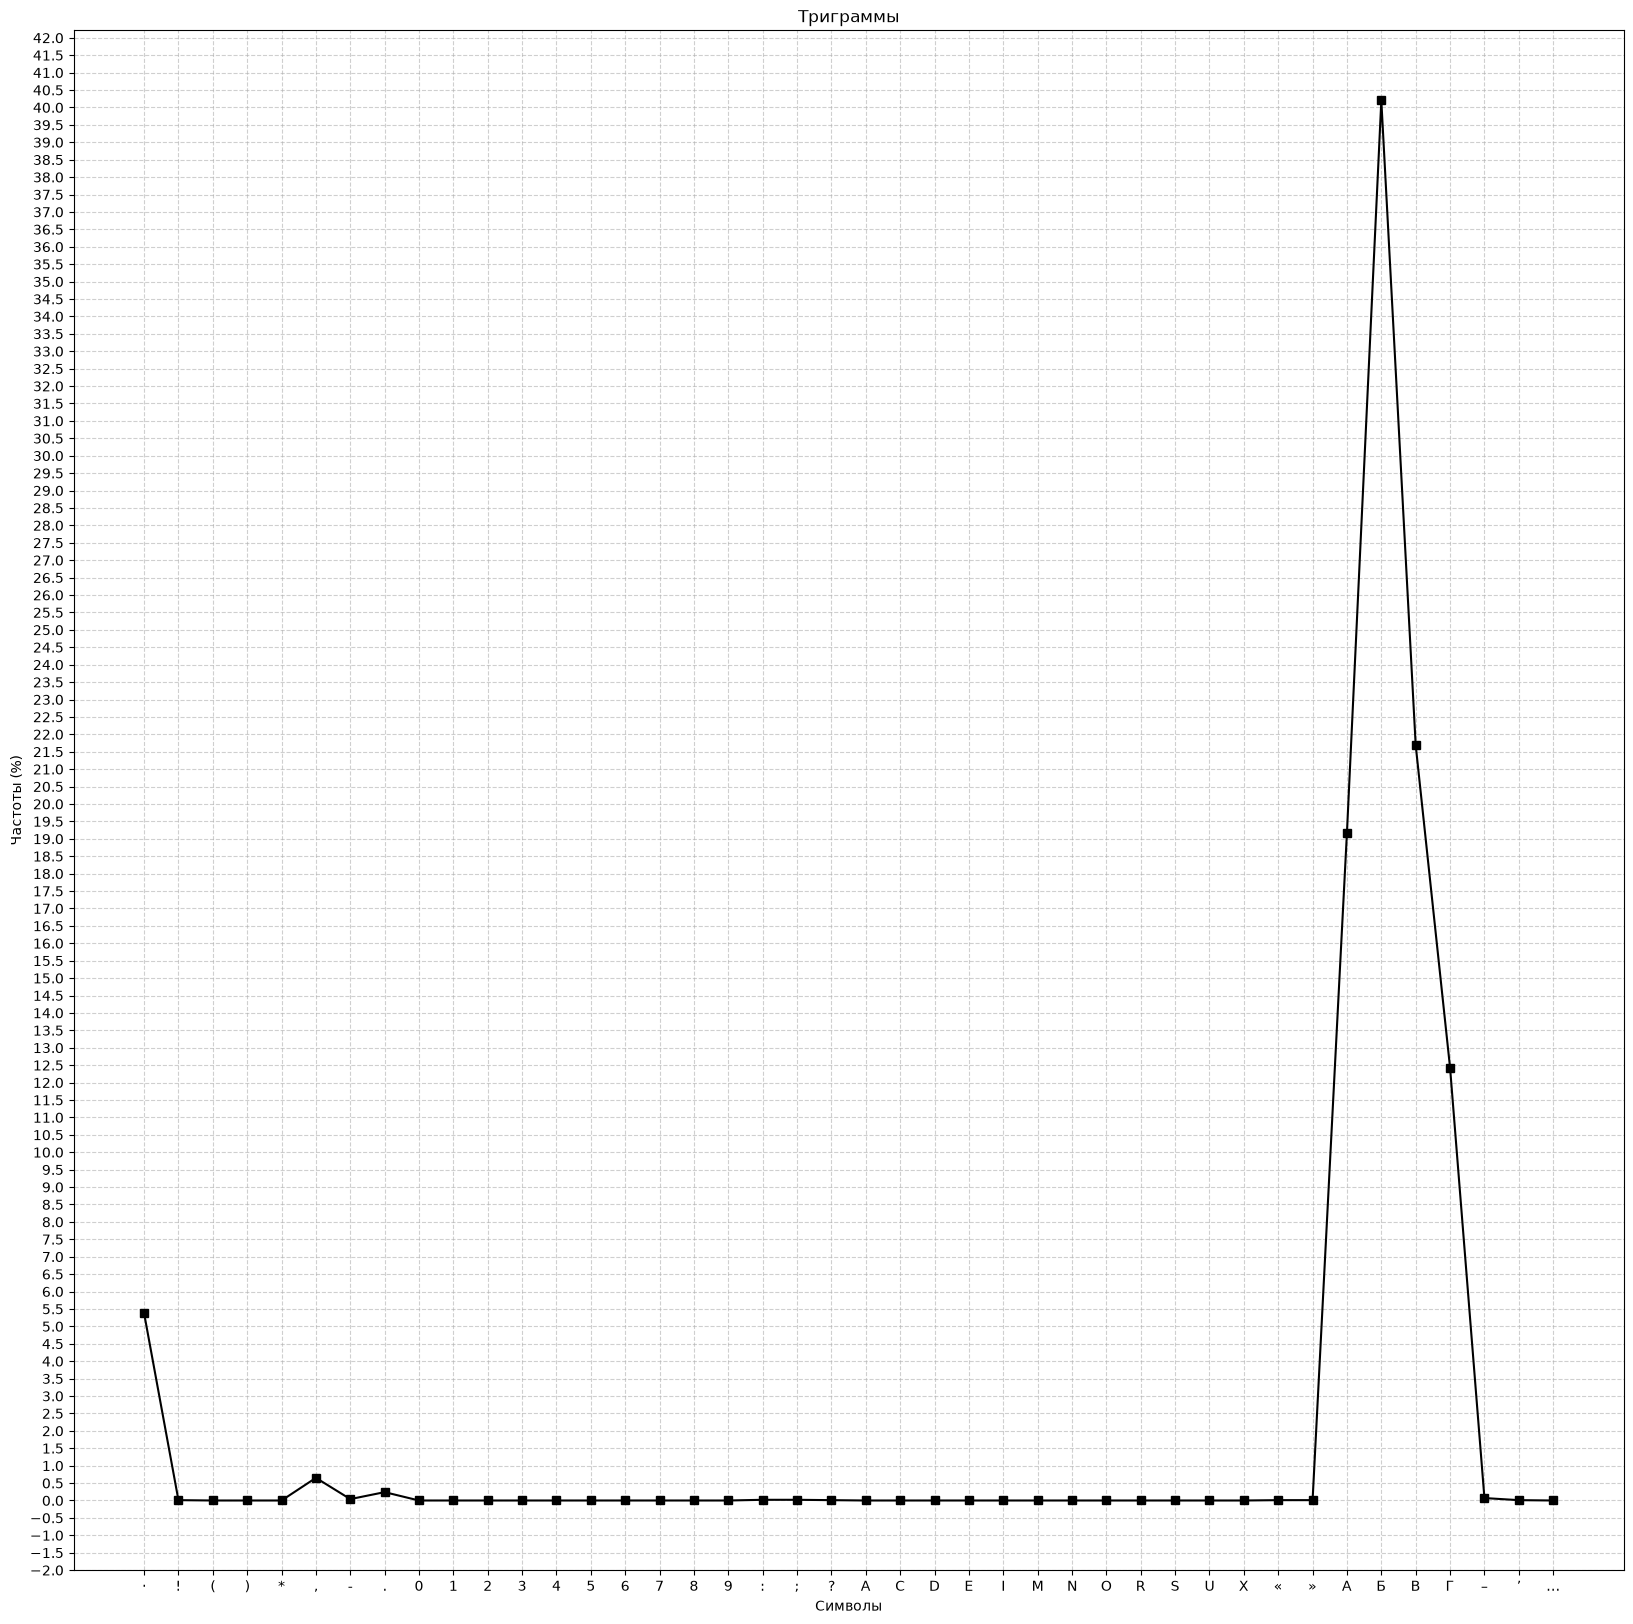

,,!,(,),*,",",-,.,0,1,2,3,4,5,6,7,8,9,:,;
Частота (%),5.38,0.01,0.0,0.0,0.0,0.65,0.04,0.24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02,0.02


,?,A,C,D,E,I,M,N,O,R,S,U,X,«,»,А,Б,В,Г,–
Частота (%),0.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.01,19.18,40.2,21.69,12.43,0.07


,’,…
Частота (%),0.01,0.0


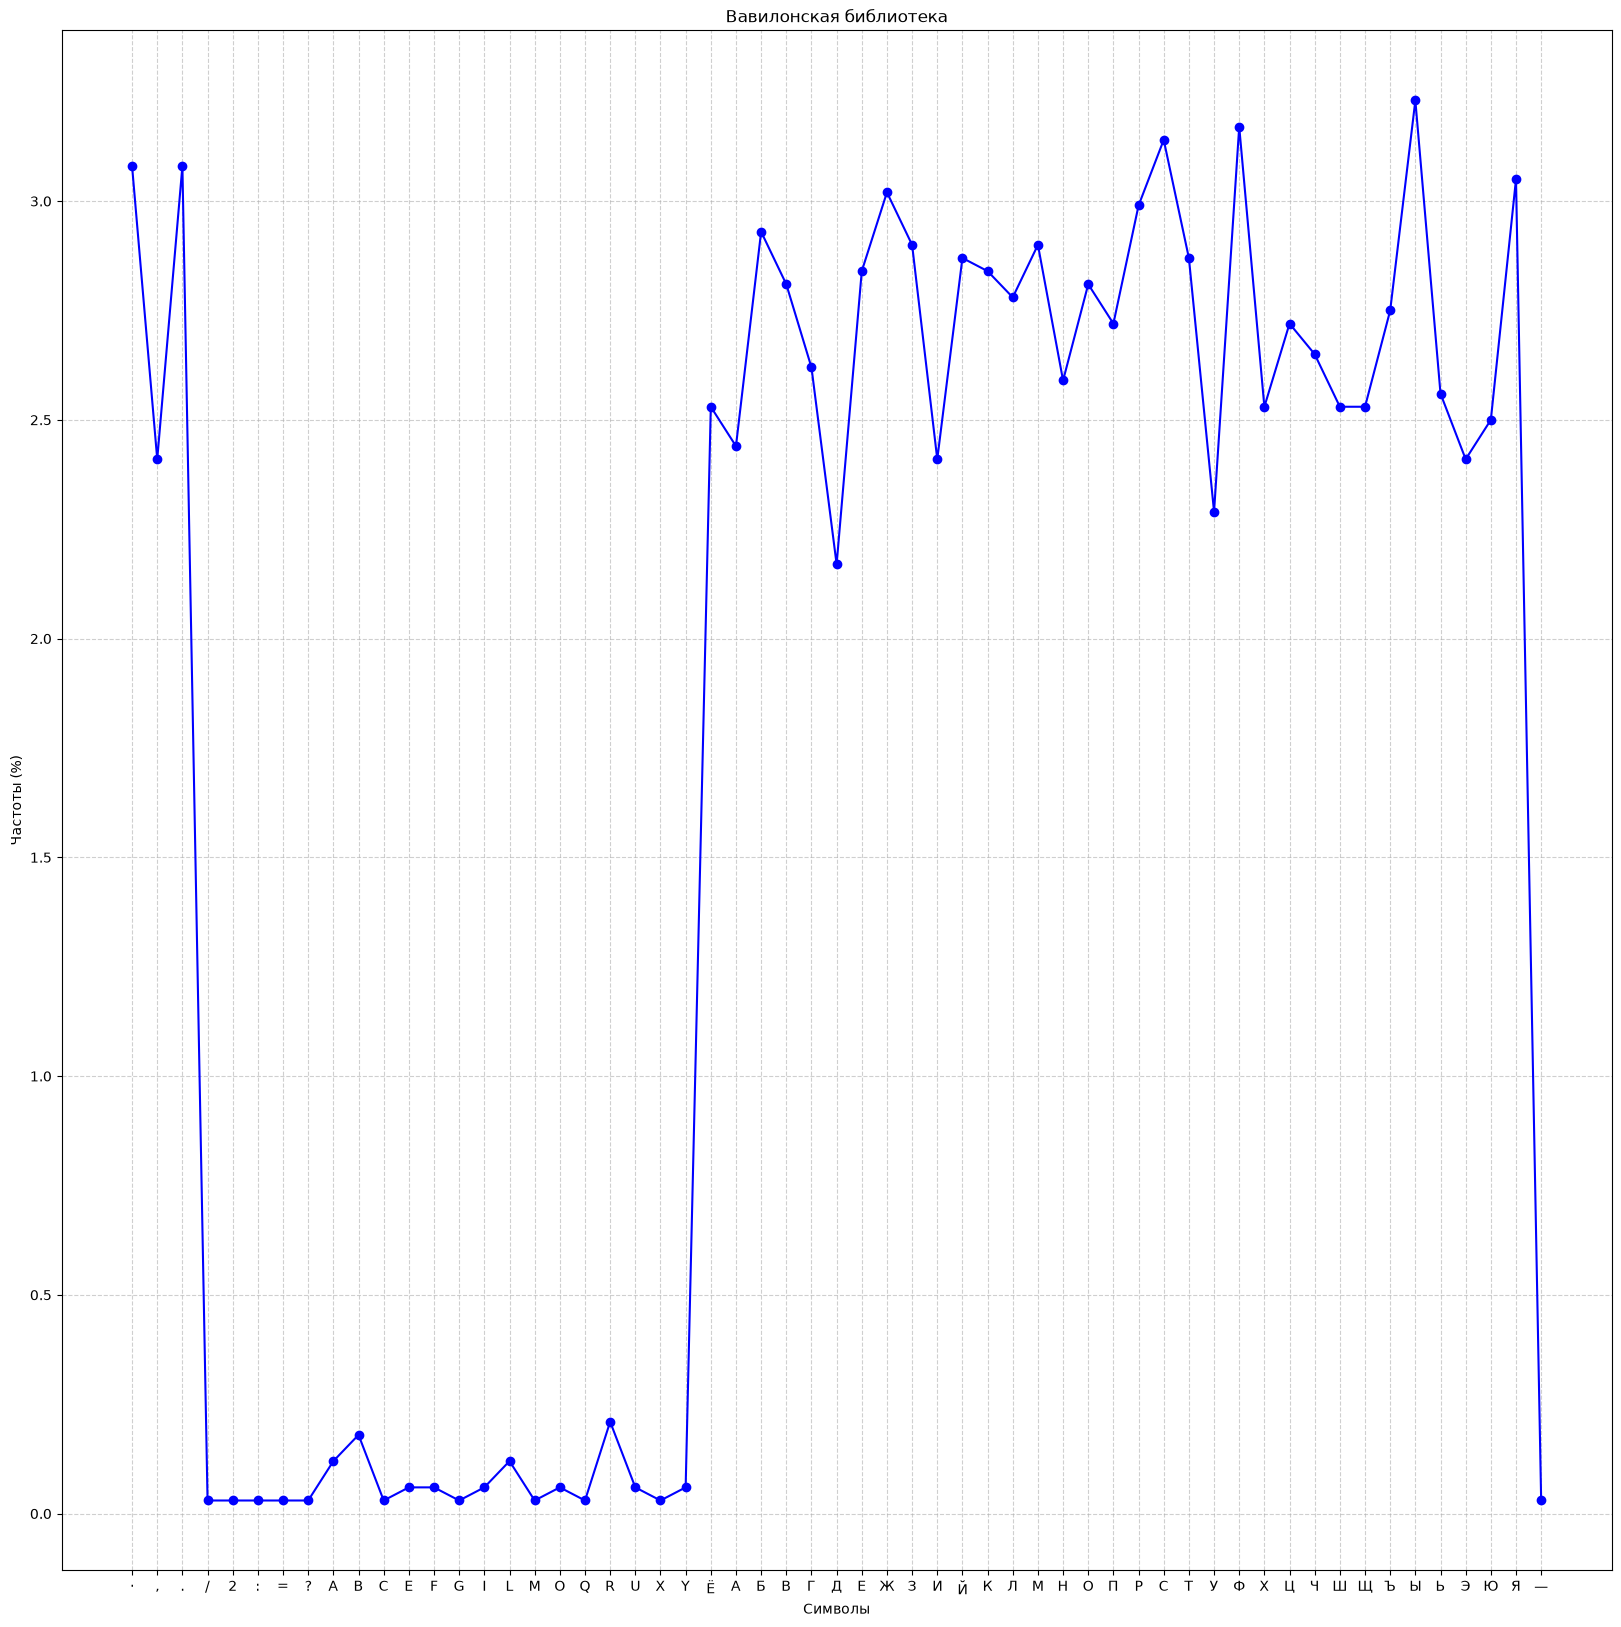

,,",",.,/,2,:,=,?,A,B,C,E,F,G,I,L,M,O,Q,R
Частота (%),3.08,2.41,3.08,0.03,0.03,0.03,0.03,0.03,0.12,0.18,0.03,0.06,0.06,0.03,0.06,0.12,0.03,0.06,0.03,0.21


,U,X,Y,Ё,А,Б,В,Г,Д,Е,Ж,З,И,Й,К,Л,М,Н,О,П
Частота (%),0.06,0.03,0.06,2.53,2.44,2.93,2.81,2.62,2.17,2.84,3.02,2.9,2.41,2.87,2.84,2.78,2.9,2.59,2.81,2.72


,Р,С,Т,У,Ф,Х,Ц,Ч,Ш,Щ,Ъ,Ы,Ь,Э,Ю,Я,—
Частота (%),2.99,3.14,2.87,2.29,3.17,2.53,2.72,2.65,2.53,2.53,2.75,3.23,2.56,2.41,2.5,3.05,0.03


In [879]:
# Настройки графиков:
# (имя файла, название графика, цвет, маркер)
graphs = [
    ('Lavkraft_Bigram.txt', 'Биграммы', 'red', 'o'),
    ('Lavkraft_Trigram.txt', 'Триграммы', 'black', 's'),
    ('Текст_из_Вавилонской_библиотеки.txt', 'Вавилонская библиотека', 'blue', 'o')
]

for filename, title, color, marker in graphs:

    with open(filename, 'r', encoding='utf-8') as file:
        encrypted_text = re.sub(r'\s+', ' ', file.read())

    char_frequencies = analize_chastot(encrypted_text)
    
    graphic(
        char_frequencies,
        0.5,
        title,
        'Символы',
        'Частоты (%)',
        color,
        marker,
        osx = 20,
        osy = 20
    )
    print_table(char_frequencies, "Частота (%)")

Функция вставки символов в исходный текст

In [880]:
# Алфавит Вавилонской библиотеки
filler_alphabet = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя., "


def insert_random_symbols(message, filler_per_char=10, seed=42):

    # Создаём генератор случайных чисел
    generator = random.Random(seed)

    result = []

    # Проходим по каждому символу сообщения
    for char in message:

        # Добавляем исходный символ
        result.append(char)

        # Генерируем случайные символы после него
        for _ in range(filler_per_char):
            random_char = generator.choice(filler_alphabet)
            result.append(random_char)

    return ''.join(result)

Текст сохранён в файл: Lavkraft_Random_Insert.txt


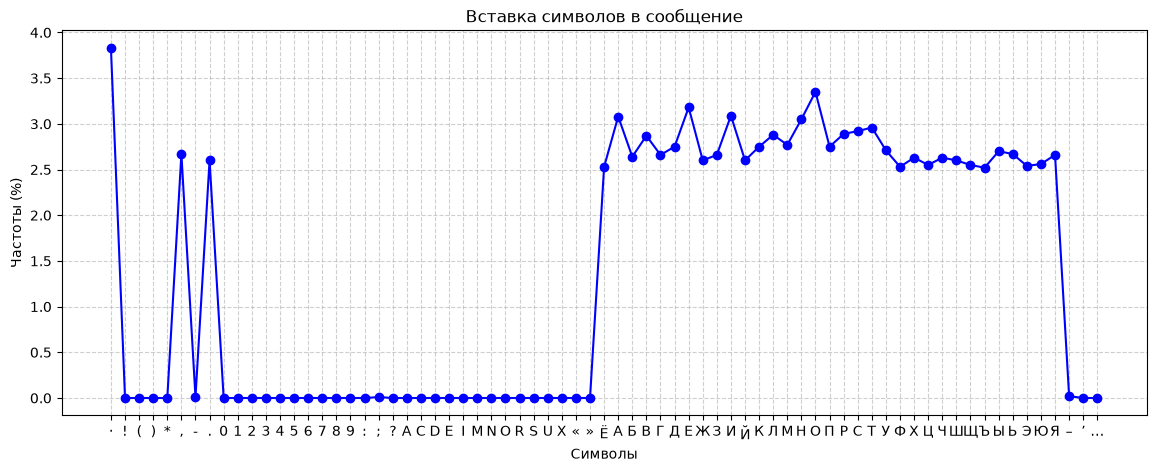

In [881]:
random_text = insert_random_symbols(
    text,
    filler_per_char=10,
    seed=42
)

save_text(random_text, "Lavkraft_Random_Insert.txt")

with open("Lavkraft_Random_Insert.txt", 'r', encoding='utf-8') as file:
    insert_in_text = file.read()

char_frequencies = analize_chastot(insert_in_text)

graphic(
        char_frequencies,
        0.5,
        "Вставка символов в сообщение",
        'Символы',
        'Частоты (%)',
        "blue",
        "o"
    )

Функция вставки символов сообщения в заранее сгенерированный случайный

In [882]:
def insert_message_into_filler(message, filler, gap=10):

    # Проверяем корректность расстояния
    if gap < 0:
        raise ValueError("Расстояние не может быть отрицательным")

    # Проверяем, хватает ли наполнителя
    if len(filler) < len(message) * gap:
        raise ValueError("Недостаточно символов наполнителя")

    result = []

    filler_pos = 0

    # Вставляем символы сообщения в текст
    for char in message:

        # Добавляем заданное количество символов книги
        result.append(filler[filler_pos:filler_pos + gap])

        # Добавляем символ сообщения
        result.append(char)

        filler_pos += gap

    # Добавляем оставшуюся часть книги
    result.append(filler[filler_pos:])

    return ''.join(result)

График частот для 1000 символов текста

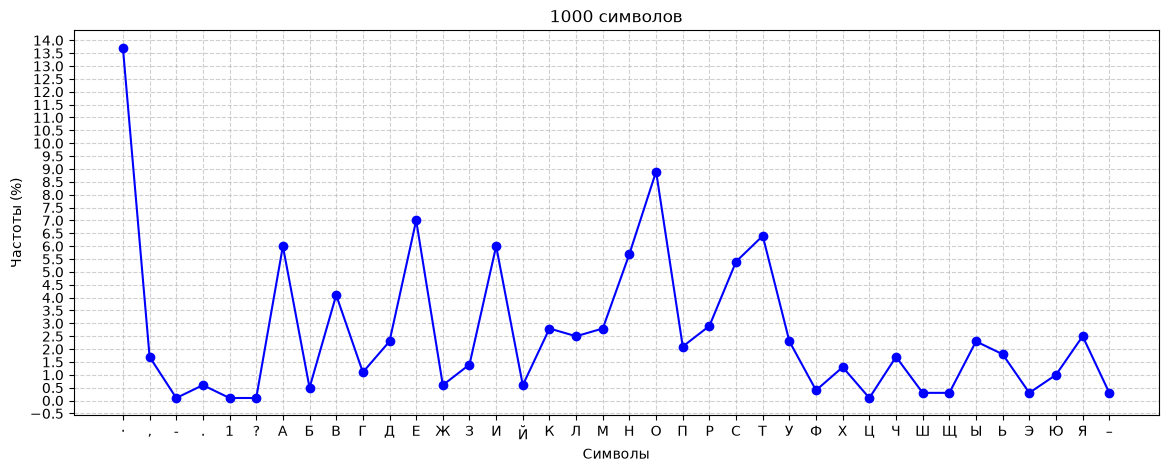

,,",",-,.,1,?,А,Б,В,Г,Д,Е,Ж,З,И,Й,К,Л,М,Н
Частоты(%),13.7,1.7,0.1,0.6,0.1,0.1,6.0,0.5,4.1,1.1,2.3,7.0,0.6,1.4,6.0,0.6,2.8,2.5,2.8,5.7


,О,П,Р,С,Т,У,Ф,Х,Ц,Ч,Ш,Щ,Ы,Ь,Э,Ю,Я,–
Частоты(%),8.9,2.1,2.9,5.4,6.4,2.3,0.4,1.3,0.1,1.7,0.3,0.3,2.3,1.8,0.3,1.0,2.5,0.3


In [883]:
one_thousand = analize_chastot(text[:1000])

graphic(
        one_thousand,
        0.5,
        "1000 символов",
        'Символы',
        'Частоты (%)',
        "blue",
        "o"
    )
print_table(one_thousand, "Частоты(%)")

График для вставки символов в текст из Вавилонской библиотеки

Текст сохранён в файл: Lavkraft_Library_Insert.txt


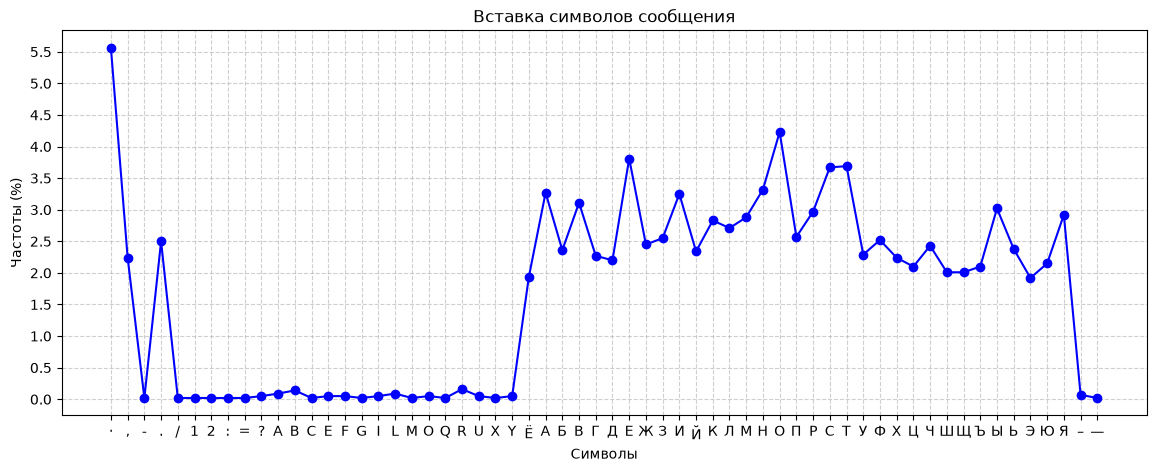

,,",",-,.,/,1,2,:,=,?,A,B,C,E,F,G,I,L,M,O
Частоты(%),5.56,2.24,0.02,2.5,0.02,0.02,0.02,0.02,0.02,0.05,0.09,0.14,0.02,0.05,0.05,0.02,0.05,0.09,0.02,0.05


,Q,R,U,X,Y,Ё,А,Б,В,Г,Д,Е,Ж,З,И,Й,К,Л,М,Н
Частоты(%),0.02,0.16,0.05,0.02,0.05,1.94,3.27,2.36,3.11,2.27,2.2,3.81,2.45,2.55,3.25,2.34,2.83,2.71,2.88,3.32


,О,П,Р,С,Т,У,Ф,Х,Ц,Ч,Ш,Щ,Ъ,Ы,Ь,Э,Ю,Я,–,—
Частоты(%),4.23,2.57,2.97,3.67,3.69,2.29,2.52,2.24,2.1,2.43,2.01,2.01,2.1,3.02,2.38,1.92,2.15,2.92,0.07,0.02


In [884]:
with open("Текст_из_Вавилонской_библиотеки.txt", 'r', encoding='utf-8') as file:
        library_text = re.sub(r'\s+', ' ', file.read())
        
inserted_text = insert_message_into_filler(
    text[:1000],
    library_text,
    gap=3
)

save_text(inserted_text, "Lavkraft_Library_Insert.txt")

with open("Lavkraft_Library_Insert.txt", 'r', encoding='utf-8') as file:
        inserted_text = file.read()

char_frequencies = analize_chastot(inserted_text)

graphic(
        char_frequencies,
        0.5,
        "Вставка символов сообщения",
        'Символы',
        'Частоты (%)',
        "blue",
        "o"
    )
print_table(char_frequencies, "Частоты(%)")

In [885]:
# Частоты символов трёх текстов
library_freq = analize_chastot(library_text)

insert_freq = analize_chastot(inserted_text)

message_freq = analize_chastot(insert_in_text)



# Формируем список графиков
data_list = [
    (library_freq, "Чистая библиотека", "blue", "o"),
    (insert_freq, "Библиотека со вставками", "red", "s"),
    (message_freq, "Текст со вставками", "green", "^"),
    (original_text_chastots, 'Оригинал', 'purple', '*')
]

In [886]:
graphic(
    data_list,
    0.5,
    "Сравнение частотных распределений",
    "Символы",
    "Частоты (%)"
)

TypeError: graphic() missing 2 required positional arguments: 'color' and 'marker'

Вынести отдельную функцию отображения графиков на одном
на одном графике отобразить сравнения символьных шифров(замены)
доработать текст
отправить преподу.